# Занятие 3. Проектирование системы биометрического контроля доступа

**Цель работы:** Спроектировать архитектуру системы контроля доступа на основе биометрии — от сенсора до принятия решения, провести анализ угроз (Threat Modeling) и построить графики работы модуля принятия решения (Decision Module: FAR, FRR, EER).

## Шаг 1. Определение сценария использования

**Выбранный сценарий:** Система биометрического контроля и управления доступом (СКУД) в **научно-исследовательскую лабораторию повышенной секретности**.
- **Режим работы:** двухфакторная верификация `1:1` (RFID смарт-карта `Subject_ID` + распознавание лица в RGB/NIR спектре).
- **Профиль модуля принятия решения:** FAR-ориентированный (высокая безопасность, минимизация вероятности ложного допуска злоумышленника).

## Шаги 2–3. Построение блок-схемы контуров Enrollment и Verification и графика FAR/FRR

Диаграмма архитектуры сохранена: ../reports/lab03_architecture_diagram.png
График FAR/FRR Decision Module сохранён: ../reports/lab03_far_frr_decision_graph.png
  - EER = 3.52% при пороге T_EER = 0.56
  - Режим удобства (T=0.45): FRR = 0.19%, FAR = 20.66%
  - Режим высокой безопасности (T=0.68): FAR = 0.18%, FRR = 27.43%


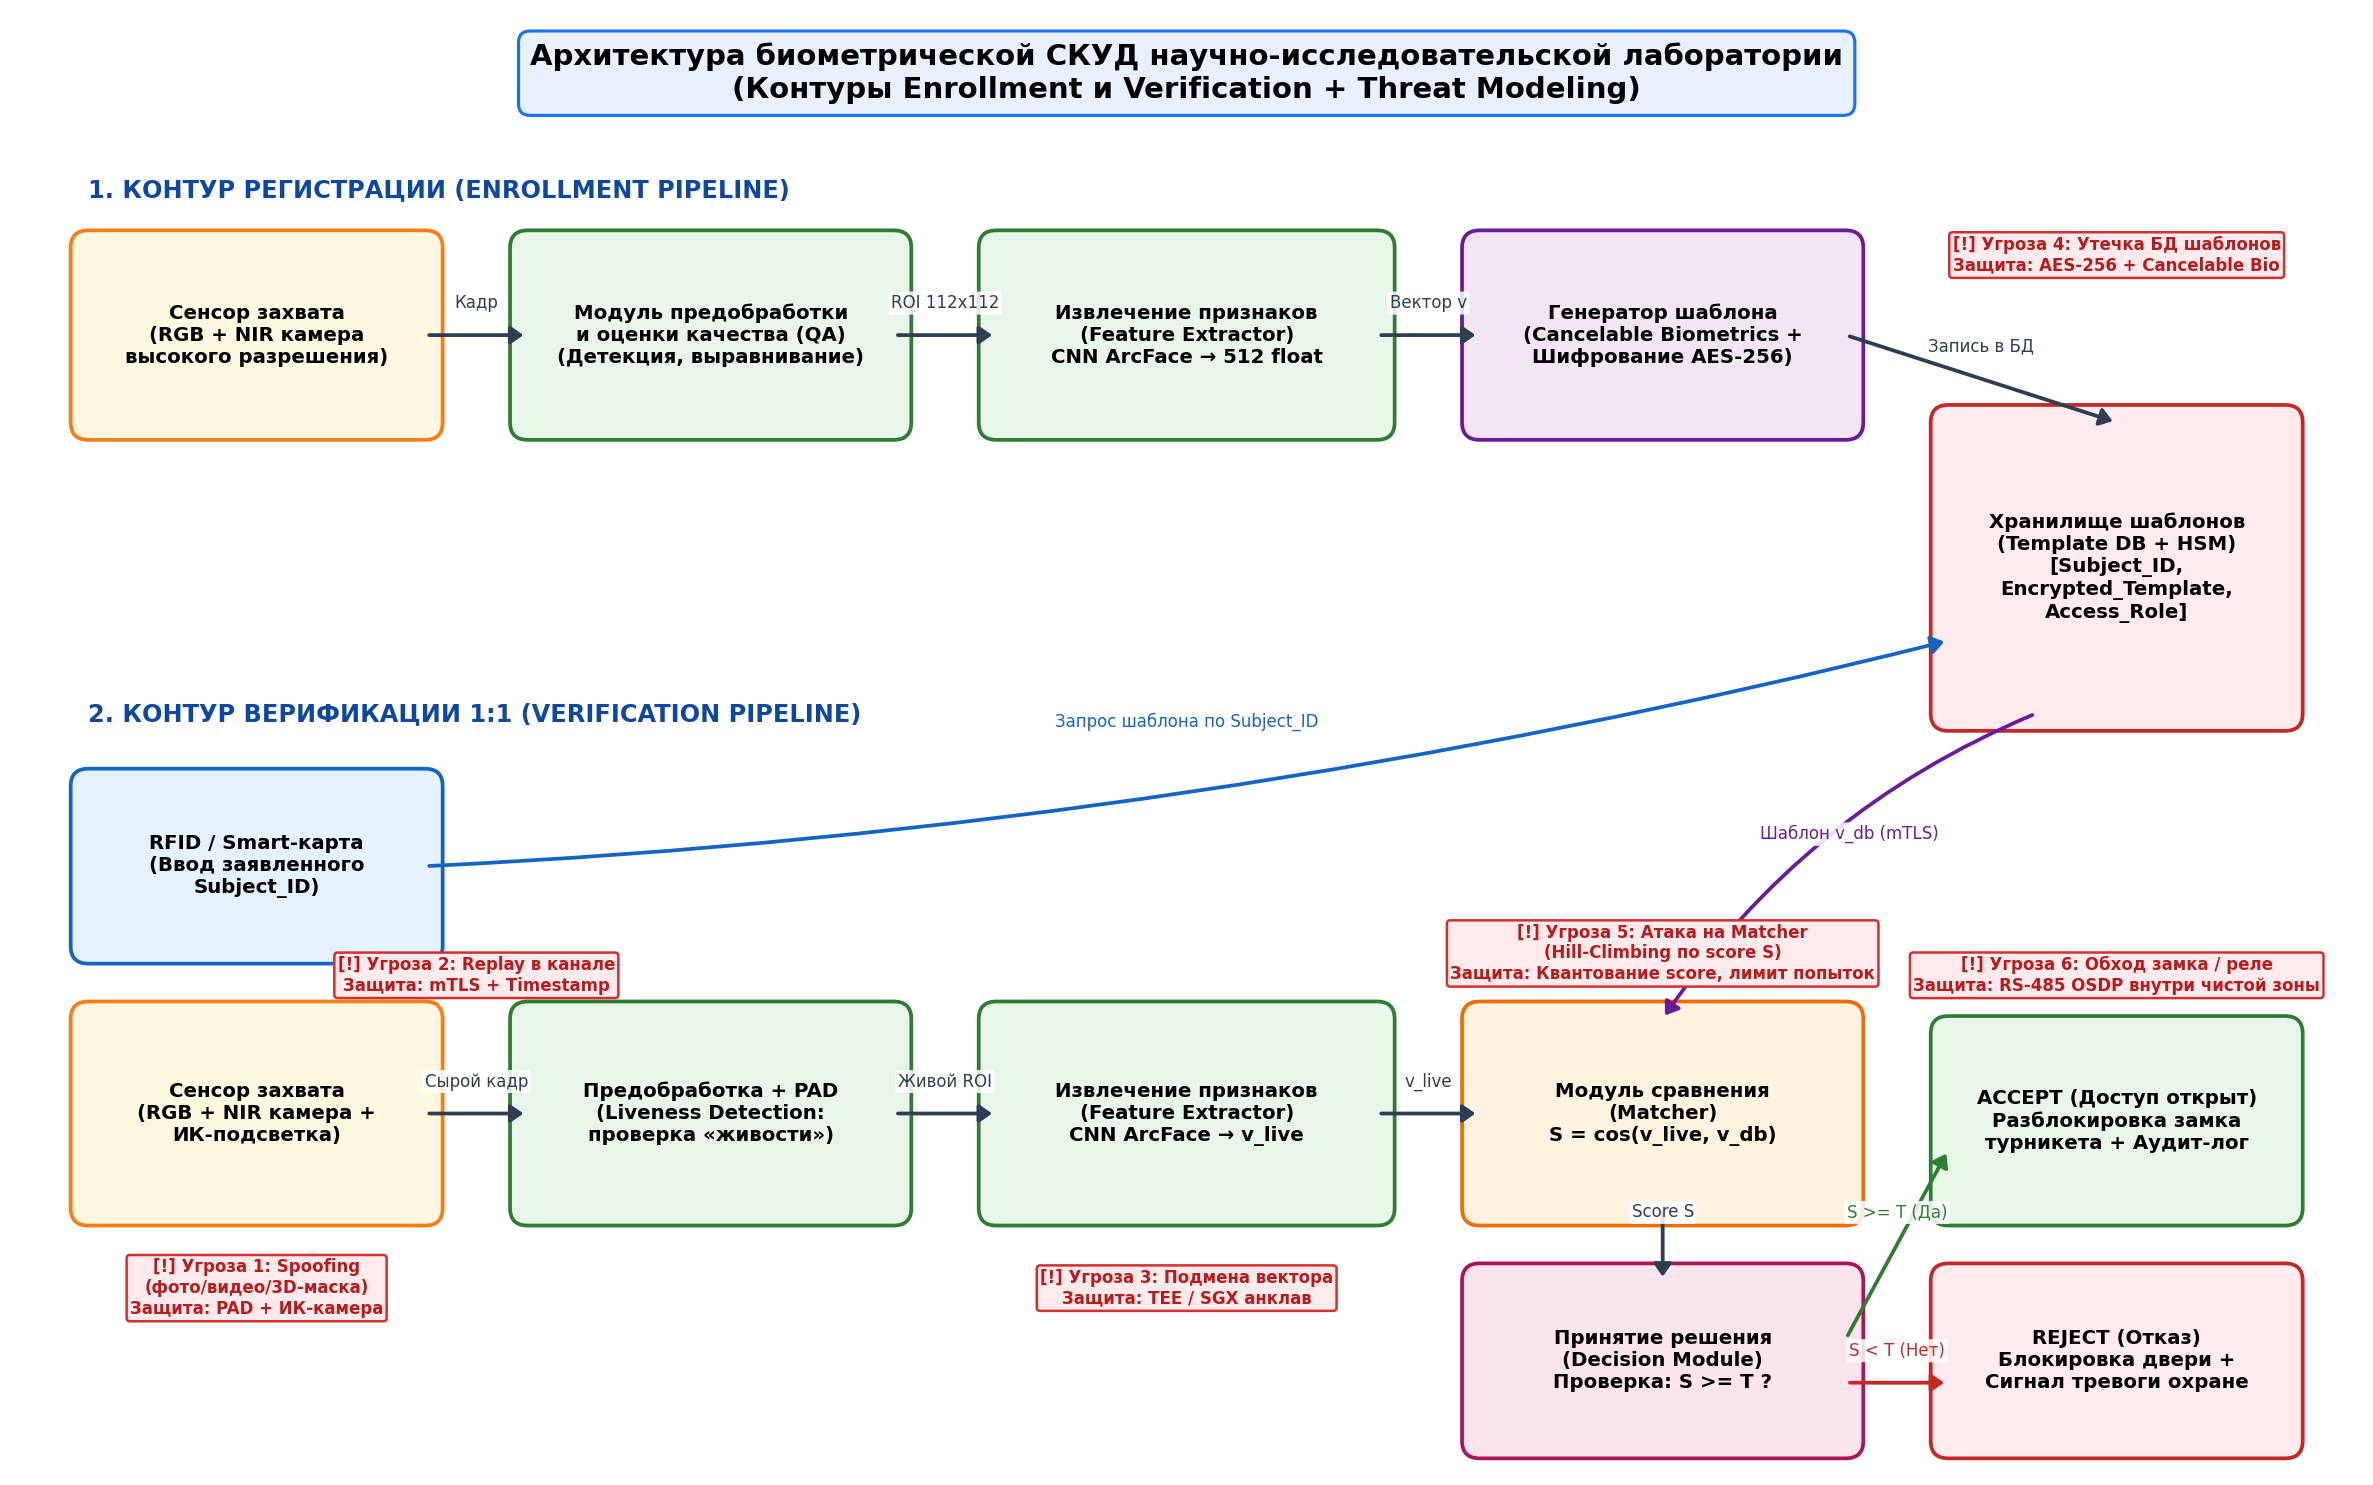

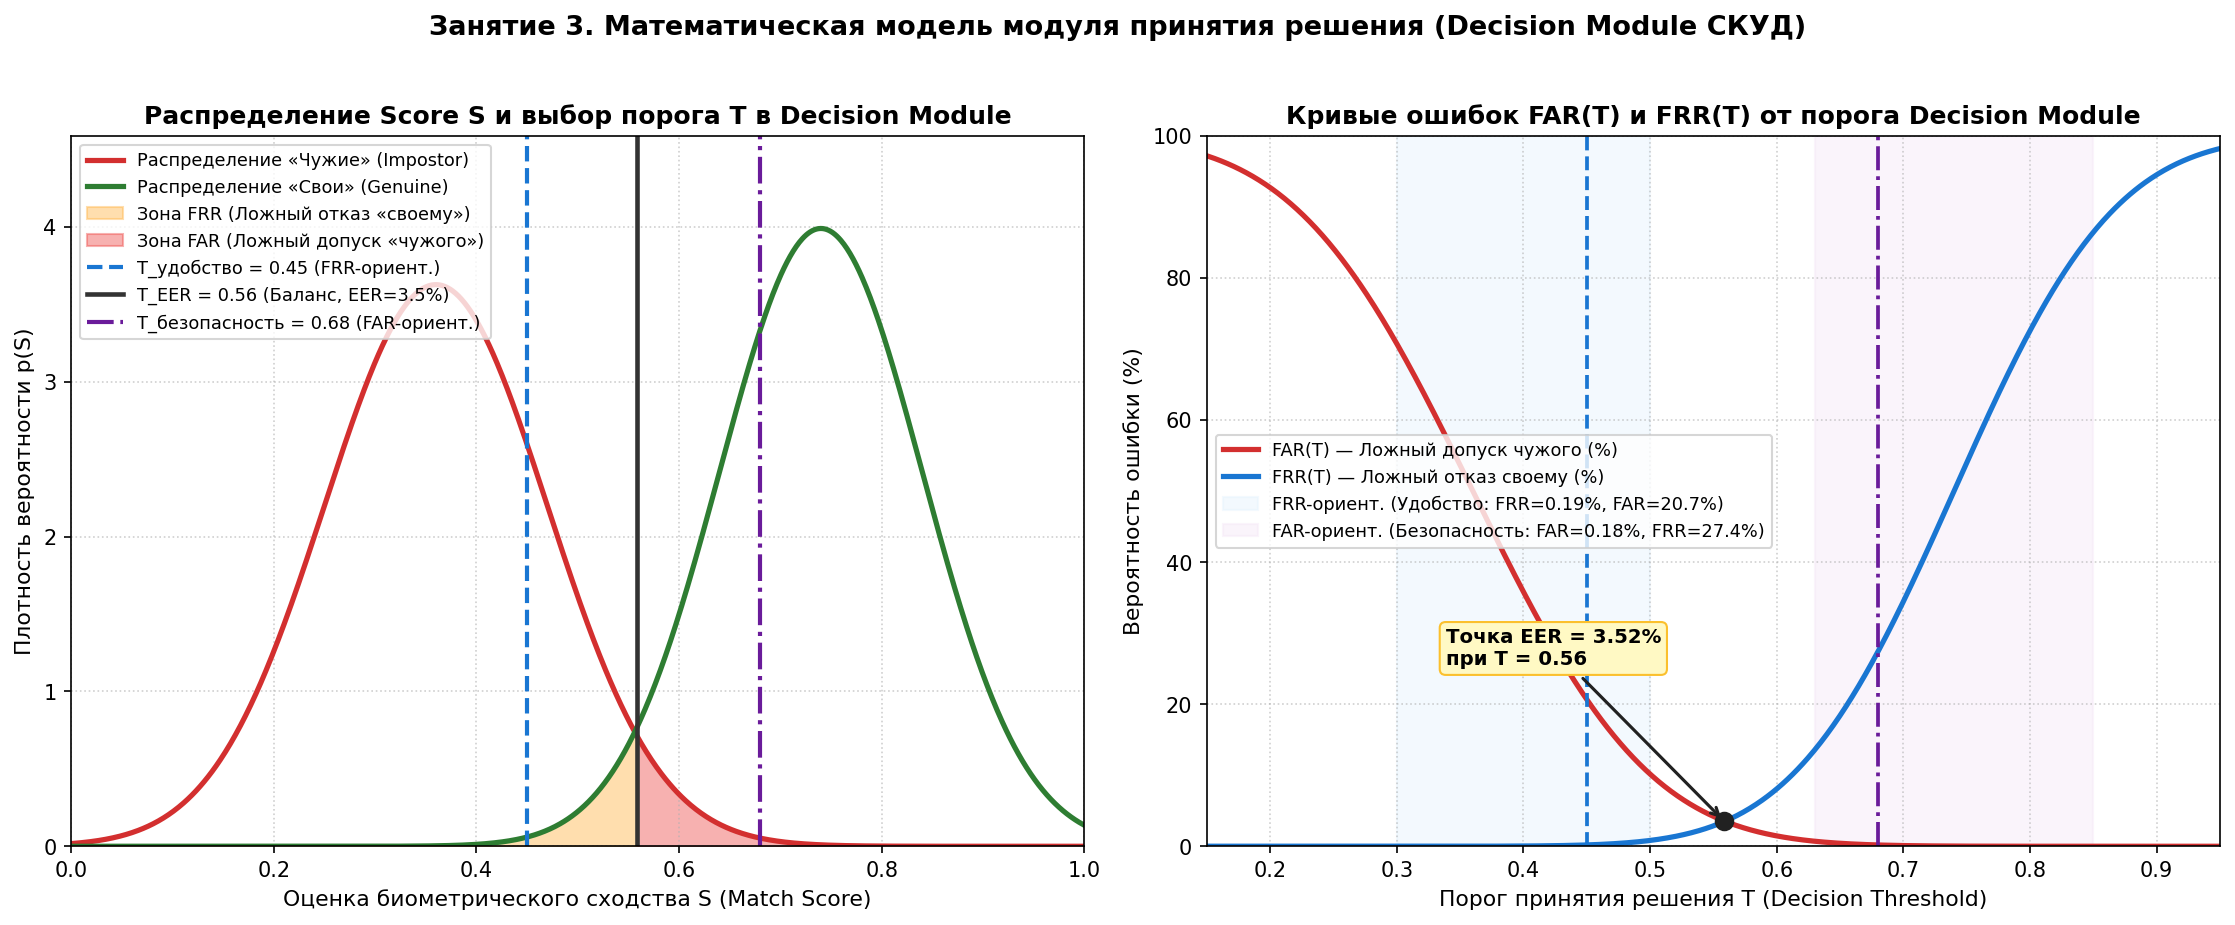

In [2]:
import os
import sys
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Сбрасываем тёмную тему IDE для корректной отрисовки текста и белого фона
plt.style.use('default')

sys.path.append(os.path.abspath('../src'))
from lab03_access_control import draw_architecture_diagram, plot_decision_module_graphs

os.makedirs('../reports', exist_ok=True)
draw_architecture_diagram('../reports/lab03_architecture_diagram.png')
plot_decision_module_graphs('../reports/lab03_far_frr_decision_graph.png')

display(Image(filename='../reports/lab03_architecture_diagram.png'))
display(Image(filename='../reports/lab03_far_frr_decision_graph.png'))

## Шаг 4. Моделирование угроз (Threat Modeling)

| № | Компонент (узел pipeline) | Потенциальная угроза | Архитектурная контрмера (Защита) |
|---|---|---|---|
| 1 | **Сенсор (Capture Device)** | Presentation Attack (Spoofing: фото, экран, 3D-маска) | Активная NIR-подсветка (850 нм) + 3D-карта глубины + нейросетевой Liveness Detection (PAD) |
| 2 | **Канал «Сенсор → Препроцессор»** | Replay-атака (перехват и повтор видеопотока) | Взаимная аутентификация mTLS, подпись кадров с `Timestamp` и одноразовым `Nonce` |
| 3 | **Модуль предобработки и PAD** | Засветка сенсора / Adversarial Patch | Оптические ИК-фильтры, ансамбль независимых PAD-детекторов |
| 4 | **Feature Extractor** | Подмена весов модели или выходного вектора | Цифровая подпись прошивки (Secure Boot), исполнение в защищённом анклаве TEE / SGX |
| 5 | **Хранилище шаблонов (Template DB)** | Утечка БД шаблонов / реконструкция лица | Отзываемые шаблоны (Cancelable Biometrics / BioHashing) + шифрование AES-256-GCM в HSM |
| 6 | **Канал «БД → Matcher»** | Атака посредника (MitM), подмена эталона | Передача по TLS 1.3, выполнение сравнения внутри защищённого сервера |
| 7 | **Модуль сравнения (Matcher)** | Hill-Climbing атака по отклику `Score S` | Квантование/скрытие `Score S` (возврат только бинарного ответа), блокировка после 3 попыток |
| 8 | **Decision Module → Замок** | Шунтирование реле замка снаружи помещения | Размещение контроллера замка в «чистой зоне», шифрованный протокол OSDP v2 (AES-128) |

## Контрольные вопросы

### 1. Почему шаблон не хранят в виде «сырого» изображения?
- **Безопасность и приватность:** биометрические данные человека нельзя перевыпустить при утечке. Из «сырого» фото злоумышленник легко изготовит муляж для обмана других систем. Зашифрованный или трансформированный вектор признаков (Cancelable Biometrics) не позволяет увидеть лицо и может быть отозван и перевыпущен с новым ключом.
- **Производительность и компактность:** вектор из 512 чисел `float32` занимает 2 КБ (против нескольких МБ у фото), инвариантен к ракурсу/освещению и сравнивается за доли миллисекунды через косинусное сходство.

### 2. На каком этапе pipeline проще всего провести атаку и почему?
- На **этапе сенсора (Spoofing / Presentation Attack)**, так как сенсор физически вынесен во внешнюю неконтролируемую зону и доступен любому посетителю, а для проведения атаки не требуются доступ к серверу или навыки взлома ПО (достаточно распечатанного фото или экрана смартфона).

### 3. Чем отличается FAR-ориентированная система (высокая безопасность) от FRR-ориентированной (высокое удобство) на уровне архитектуры decision-модуля?
- **FAR-ориентированная система** использует высокий порог $T > T_{\text{EER}}$ ($\text{FAR} \to 0$), конъюнктивное правило слияния факторов (`Card AND Face AND Liveness`), каскадную проверку серии из 2–3 кадров для компенсации повышенного одиночного FRR и жёсткую блокировку с тревожным оповещением при превышении лимита отказов.
- **FRR-ориентированная система** использует сниженный порог $T < T_{\text{EER}}$ ($\text{FRR} \to 0$), мгновенное принятие решения по первому кадру и мягкий fallback на резервный метод (PIN/пропуск) без блокировки пользователя.